In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create an output directory to keep Colab files organized
output_dir = 'eda_outputs'
os.makedirs(output_dir, exist_ok=True)

# Load the dataset
file_path = 'Airline_Delay_Cause.csv'
df = pd.read_csv(file_path)

print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.")

Dataset loaded successfully with 398233 rows and 21 columns.


In [ ]:
# Calculate descriptive statistics for all columns
desc_stats = df.describe(include='all')

# Display in Colab
display(desc_stats)

# Save to Colab storage
desc_stats.to_csv(f'{output_dir}/descriptive_statistics.csv')
print("Descriptive statistics saved to descriptive_statistics.csv")

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
count,398233.000000,398233.000000,398233,398233,398233,398233,397576.000000,397283.000000,397576.000000,397576.000000,...,397576.000000,397576.000000,397576.000000,397576.000000,397576.000000,397576.000000,397576.000000,397576.000000,397576.000000,397576.000000
unique,NaN,NaN,38,51,425,449,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,OO,SkyWest Airlines Inc.,DTW,"Detroit, MI: Detroit Metro Wayne County",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,46212,46212,3688,3688,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2014.421344,6.524078,NaN,NaN,NaN,NaN,361.663536,69.593947,20.540331,2.508231,...,0.172630,24.111972,6.789323,0.834168,4167.479403,1309.317177,223.331064,1026.011882,7.144337,1601.667661
std,6.474505,3.463111,NaN,NaN,NaN,NaN,993.947394,193.608821,48.314208,9.570840,...,0.826248,74.414722,35.086108,3.792889,12755.983464,3824.984307,883.700515,4335.789252,39.129575,5154.585282
min,2003.000000,1.000000,NaN,NaN,NaN,NaN,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-19.000000,0.000000,0.000000
25%,2009.000000,4.000000,NaN,NaN,NaN,NaN,56.000000,8.000000,2.790000,0.000000,...,0.000000,1.510000,0.000000,0.000000,405.000000,134.000000,0.000000,49.000000,0.000000,75.000000
50%,2015.000000,7.000000,NaN,NaN,NaN,NaN,113.000000,21.000000,7.510000,0.510000,...,0.000000,5.490000,1.000000,0.000000,1140.000000,410.000000,22.000000,183.000000,0.000000,341.000000
75%,2020.000000,10.000000,NaN,NaN,NaN,NaN,255.000000,52.000000,18.650000,2.000000,...,0.000000,16.150000,4.000000,1.000000,2974.000000,1075.000000,155.000000,555.000000,0.000000,1089.000000


Descriptive statistics saved to descriptive_statistics.csv


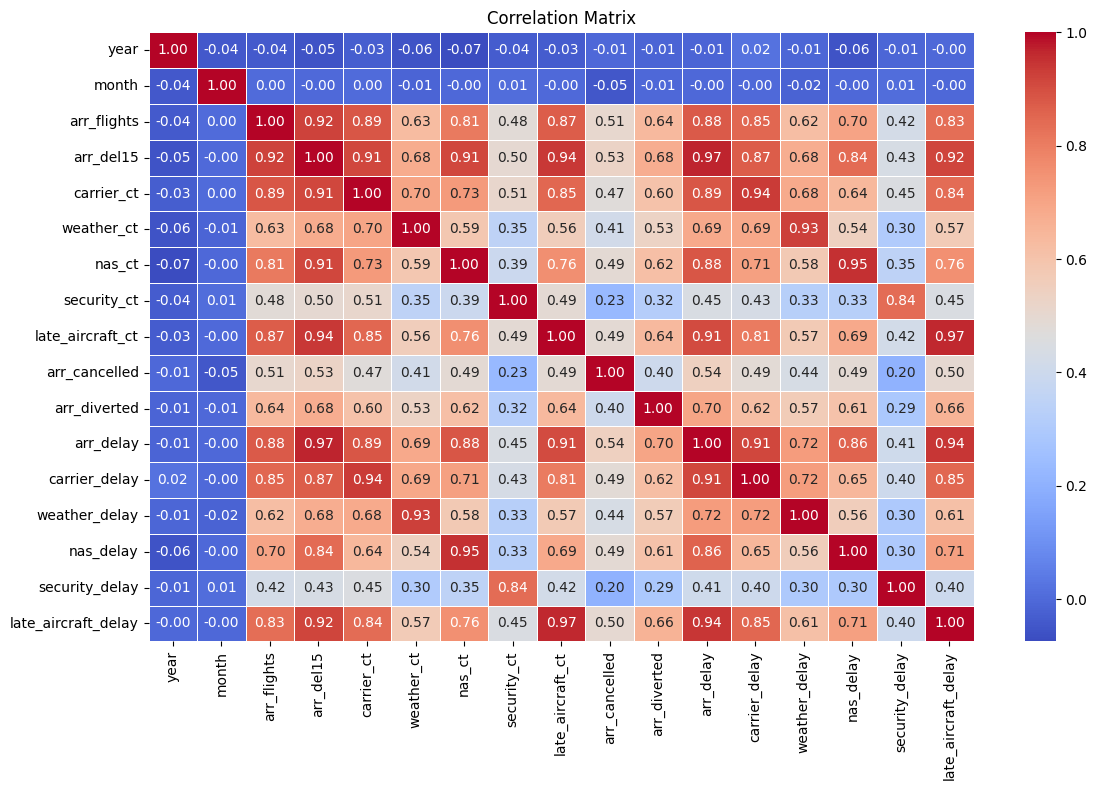

Correlation matrix and heatmap saved.


In [ ]:
# Calculate correlation matrix for numeric columns only
corr_matrix = df.corr(numeric_only=True)

# Plot the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.tight_layout()

# Save plot and data
plt.savefig(f'{output_dir}/correlation_heatmap.png')
corr_matrix.to_csv(f'{output_dir}/correlation_matrix.csv')
plt.show()

print("Correlation matrix and heatmap saved.")

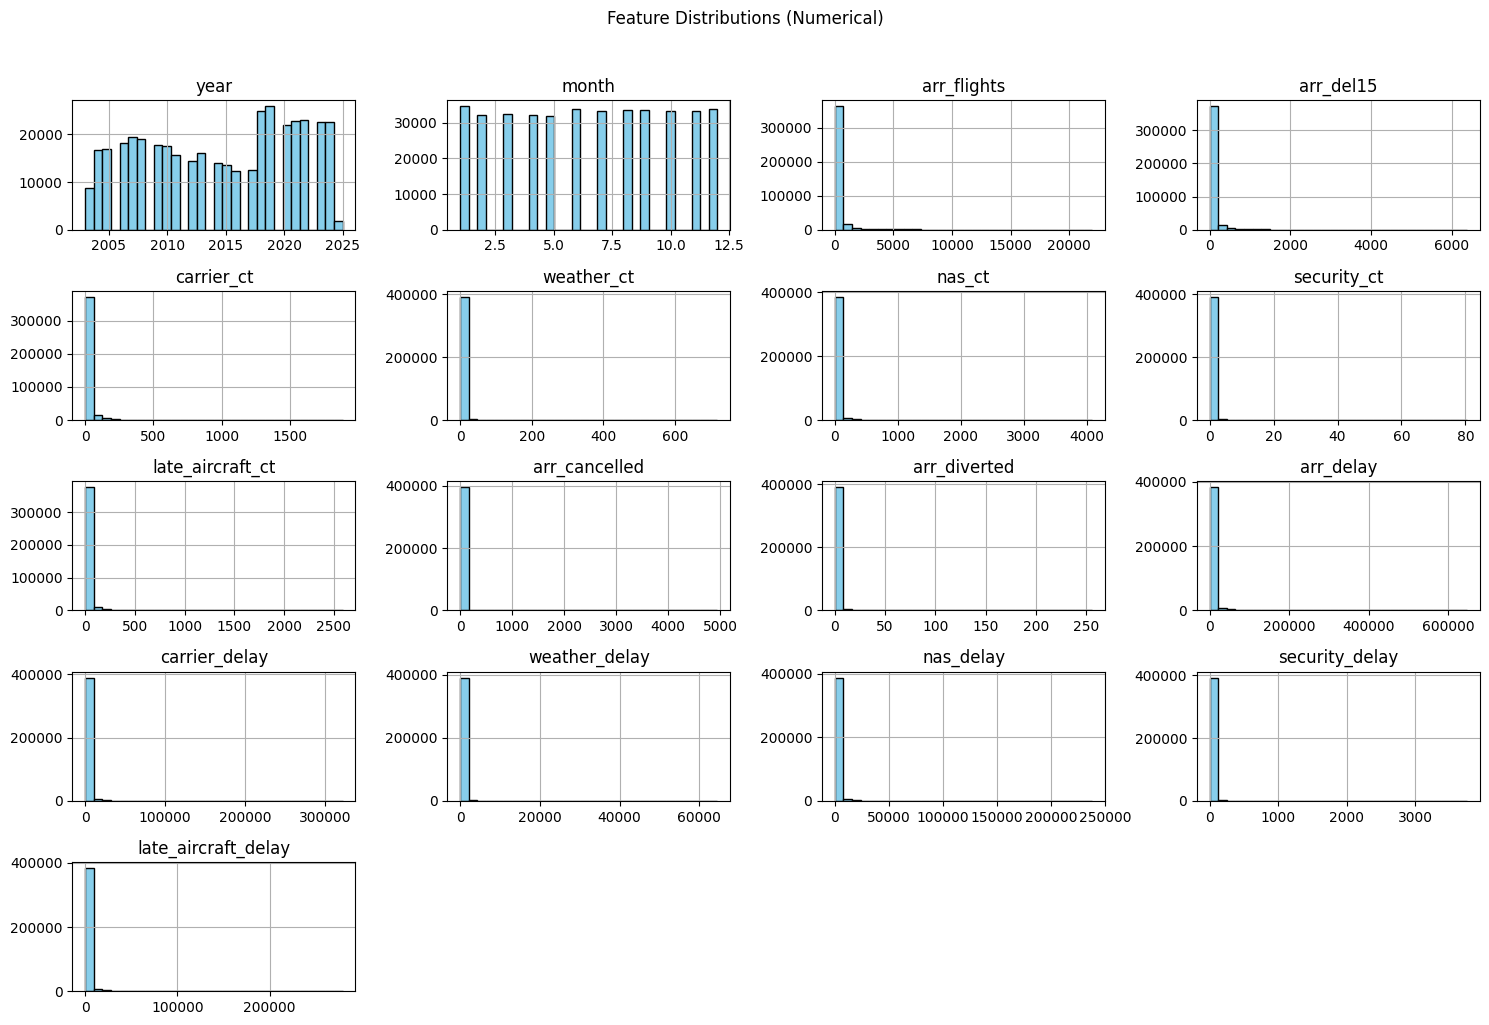

Feature distribution plots saved to feature_distributions.png


In [ ]:
# Select numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Plot histograms
df[numeric_cols].hist(bins=30, figsize=(15, 10), color='skyblue', edgecolor='black')
plt.suptitle('Feature Distributions (Numerical)', y=1.02)
plt.tight_layout()

# Save plot
plt.savefig(f'{output_dir}/feature_distributions.png')
plt.show()

print("Feature distribution plots saved to feature_distributions.png")

In [ ]:
# Calculate skewness for numeric columns
skewness = df[numeric_cols].skew().sort_values(ascending=False)
skewness_df = pd.DataFrame(skewness, columns=['Skewness'])

# Display and save
display(skewness_df)
skewness_df.to_csv(f'{output_dir}/skewness.csv')

print("Skewness metrics saved to skewness.csv")

,Skewness
arr_cancelled,32.303876
security_delay,22.305094
weather_ct,20.959543
weather_delay,16.969902
arr_diverted,16.774872
security_ct,16.493345
nas_delay,13.988961
carrier_delay,12.724300
nas_ct,12.085181
late_aircraft_delay,10.530853


Skewness metrics saved to skewness.csv


In [ ]:
# Calculate missing values and percentages
missing_val = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Values': missing_val, 'Percentage (%)': missing_pct})

# Filter out columns with 0 missing values for a cleaner view
missing_df = missing_df[missing_df['Missing Values'] > 0].sort_values(by='Percentage (%)', ascending=False)

# Display and save
display(missing_df)
missing_df.to_csv(f'{output_dir}/missing_values.csv')

print("Missing values report saved to missing_values.csv")

,Missing Values,Percentage (%)
arr_del15,950,0.238554
arr_flights,657,0.164979
carrier_ct,657,0.164979
weather_ct,657,0.164979
nas_ct,657,0.164979
security_ct,657,0.164979
late_aircraft_ct,657,0.164979
arr_cancelled,657,0.164979
arr_diverted,657,0.164979
arr_delay,657,0.164979


Missing values report saved to missing_values.csv


In [ ]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows found: {duplicate_count}")

# Extract duplicate rows if any exist
if duplicate_count > 0:
    duplicates_df = df[df.duplicated(keep=False)].sort_values(by=list(df.columns))
    duplicates_df.to_csv(f'{output_dir}/duplicate_rows.csv', index=False)
    print("Duplicate rows saved to duplicate_rows.csv")
else:
    print("No duplicate rows to save.")

Total duplicate rows found: 0
No duplicate rows to save.


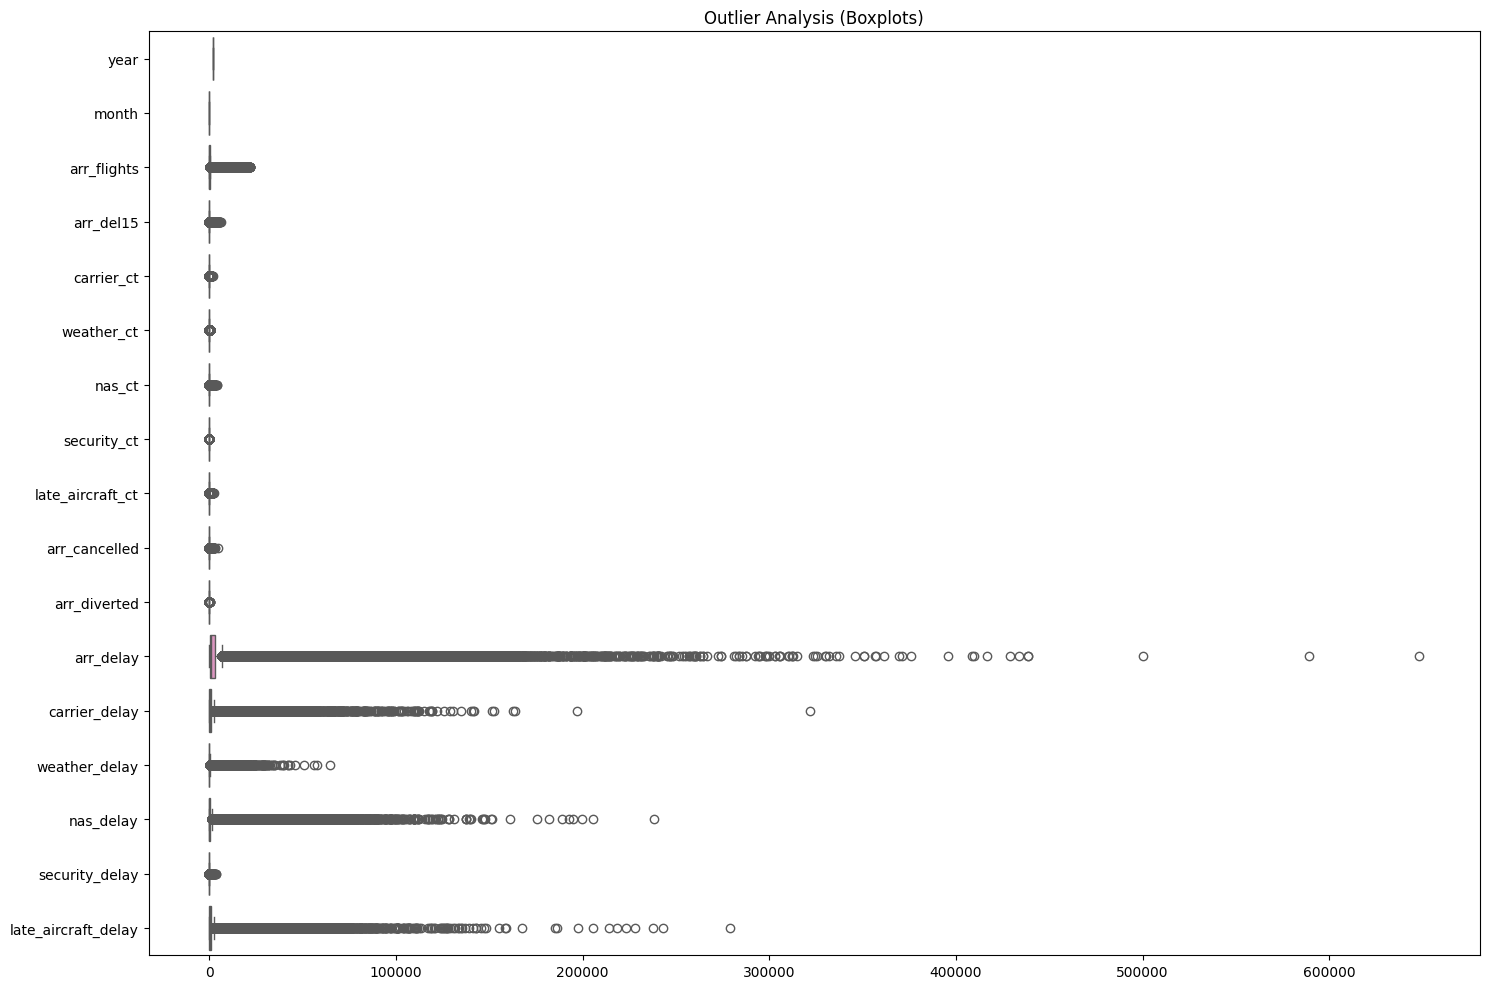

,Outlier Count
arr_flights,46743
arr_del15,45286
carrier_ct,41295
weather_ct,42696
nas_ct,47536
security_ct,50860
late_aircraft_ct,47051
arr_cancelled,45083
arr_diverted,26782
arr_delay,45498


Outlier boxplots and counts saved.


In [ ]:
# 1. Visualizing Outliers with Boxplots
plt.figure(figsize=(15, 10))
sns.boxplot(data=df[numeric_cols], orient='h', palette='Set2')
plt.title('Outlier Analysis (Boxplots)')
plt.tight_layout()
plt.savefig(f'{output_dir}/outliers_boxplot.png')
plt.show()

# 2. Quantifying Outliers using IQR
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

# Count outliers per column
outliers_count = ((df[numeric_cols] < (Q1 - 1.5 * IQR)) | (df[numeric_cols] > (Q3 + 1.5 * IQR))).sum()
outliers_df = pd.DataFrame(outliers_count, columns=['Outlier Count'])

# Display and save
display(outliers_df[outliers_df['Outlier Count'] > 0])
outliers_df.to_csv(f'{output_dir}/outliers_count.csv')

print("Outlier boxplots and counts saved.")

In [ ]:
# Select categorical columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

# Calculate value counts for each categorical feature
imbalance_reports = []
for col in categorical_cols:
    counts = df[col].value_counts(normalize=True) * 100
    counts_df = counts.reset_index()
    counts_df.columns = [col, 'Percentage (%)']

    # Save individual reports
    counts_df.to_csv(f'{output_dir}/imbalance_{col}.csv', index=False)
    imbalance_reports.append(counts_df.head(5)) # Store top 5 for display
    print(f"Top 5 categories in '{col}':")
    display(counts_df.head(5))
    print("-" * 30)

print("Class imbalance reports saved for categorical columns.")

Top 5 categories in 'carrier':


,carrier,Percentage (%)
0,OO,11.604262
1,DL,8.062617
2,MQ,7.453174
3,EV,6.733495
4,AA,5.949030


------------------------------
Top 5 categories in 'carrier_name':


,carrier_name,Percentage (%)
0,SkyWest Airlines Inc.,11.604262
1,ExpressJet Airlines Inc.,6.196624
2,Delta Air Lines Inc.,5.167829
3,Mesa Airlines Inc.,4.311044
4,American Eagle Airlines Inc.,3.869343


------------------------------
Top 5 categories in 'airport':


,airport,Percentage (%)
0,DTW,0.926091
1,PIT,0.914540
2,IND,0.913033
3,MCI,0.906002
4,RDU,0.878380


------------------------------
Top 5 categories in 'airport_name':


,airport_name,Percentage (%)
0,"Detroit, MI: Detroit Metro Wayne County",0.926091
1,"Pittsburgh, PA: Pittsburgh International",0.914540
2,"Indianapolis, IN: Indianapolis International",0.913033
3,"Kansas City, MO: Kansas City International",0.906002
4,"Raleigh/Durham, NC: Raleigh-Durham International",0.878380


------------------------------
Class imbalance reports saved for categorical columns.


In [ ]:
noise_report = {}

# 1. Categorical Noise (rare categories appearing only once)
for col in categorical_cols:
    val_counts = df[col].value_counts()
    rare_vals = val_counts[val_counts == 1].index.tolist()
    if rare_vals:
        noise_report[col] = f"{len(rare_vals)} rare categories (frequency = 1)"

# 2. Numerical Noise (extreme variations / constant values)
for col in numeric_cols:
    std_dev = df[col].std()
    if std_dev == 0:
        noise_report[col] = "Constant value (Zero variance)"
    elif df[col].nunique() == len(df):
        noise_report[col] = "All values are unique (Potential ID/Noise)"

noise_df = pd.DataFrame(list(noise_report.items()), columns=['Column', 'Noise Description'])
display(noise_df)
noise_df.to_csv(f'{output_dir}/noise_analysis.csv', index=False)

print("Noise analysis saved to noise_analysis.csv")

,Column,Noise Description
0,airport,9 rare categories (frequency = 1)
1,airport_name,10 rare categories (frequency = 1)


Noise analysis saved to noise_analysis.csv


In [ ]:
inconsistencies = []

# 1. Check for unexpected negative values in numeric columns (Assuming delays shouldn't be negative)
for col in numeric_cols:
    negative_count = (df[col] < 0).sum()
    if negative_count > 0:
        inconsistencies.append({'Column': col, 'Issue': f'{negative_count} negative values found'})

# 2. Check for mixed data types in object columns
for col in categorical_cols:
    mixed_types = df[col].apply(type).nunique() > 1
    if mixed_types:
        inconsistencies.append({'Column': col, 'Issue': 'Mixed data types found (e.g., int and str)'})

inconsistencies_df = pd.DataFrame(inconsistencies)
display(inconsistencies_df)

if not inconsistencies_df.empty:
    inconsistencies_df.to_csv(f'{output_dir}/inconsistencies.csv', index=False)
    print("Inconsistencies report saved to inconsistencies.csv")
else:
    print("No negative values or mixed data types detected.")

,Column,Issue
0,nas_ct,1 negative values found
1,nas_delay,2 negative values found


Inconsistencies report saved to inconsistencies.csv


In [ ]:
# new noise
noise_details = []

# 1. Categorical Noise (extracting the exact rare categories)
for col in categorical_cols:
    val_counts = df[col].value_counts()
    rare_vals = val_counts[val_counts == 1].index.tolist()
    if rare_vals:
        noise_details.append({
            'Column': col,
            'Count': len(rare_vals),
            'Rare Values': ", ".join(map(str, rare_vals)) # Lists the actual names
        })

# 2. Numerical Noise (extreme variations / constant values)
for col in numeric_cols:
    std_dev = df[col].std()
    if std_dev == 0:
        noise_details.append({'Column': col, 'Count': 'N/A', 'Rare Values': "Constant value (Zero variance)"})
    elif df[col].nunique() == len(df):
        noise_details.append({'Column': col, 'Count': 'N/A', 'Rare Values': "All values are unique (Potential ID/Noise)"})

# Display and save
noise_details_df = pd.DataFrame(noise_details)
display(noise_details_df)

noise_details_df.to_csv(f'{output_dir}/noise_analysis_detailed.csv', index=False)
print("Detailed noise analysis saved to noise_analysis_detailed.csv")

,Column,Count,Rare Values
0,airport,9,"FNL, TKI, ENV, YNG, MKC, GLH, RCA, SKA, CBM"
1,airport_name,10,"Greenville, MS: Greenville Mid Delta, Rapid Ci..."


Detailed noise analysis saved to noise_analysis_detailed.csv


In [ ]:
# new inconsistencies
inconsistencies = []

# 1. Check for unexpected negative values in numeric columns
for col in numeric_cols:
    negative_vals = df[df[col] < 0][col].unique().tolist()
    if negative_vals:
        inconsistencies.append({
            'Column': col,
            'Issue': f'{len(negative_vals)} unique negative values found',
            'Specific Inconsistent Values': ", ".join(map(str, negative_vals))
        })

# 2. Check for mixed data types in categorical columns
for col in categorical_cols:
    types_in_col = df[col].apply(type).unique()
    if len(types_in_col) > 1:
        # Get the names of the data types (e.g., 'int', 'str', 'float')
        type_names = [t.__name__ for t in types_in_col]
        inconsistencies.append({
            'Column': col,
            'Issue': 'Mixed data types found',
            'Specific Inconsistent Values': ", ".join(type_names)
        })

# Display and save
inconsistencies_df = pd.DataFrame(inconsistencies)
display(inconsistencies_df)

if not inconsistencies_df.empty:
    inconsistencies_df.to_csv(f'{output_dir}/inconsistencies_detailed.csv', index=False)
    print("Detailed inconsistencies report saved to inconsistencies_detailed.csv")
else:
    print("No negative values or mixed data types detected.")

,Column,Issue,Specific Inconsistent Values
0,nas_ct,1 unique negative values found,-0.01
1,nas_delay,2 unique negative values found,"-1.0, -19.0"


Detailed inconsistencies report saved to inconsistencies_detailed.csv


Output folder created: /content/Flight_Delay_Part_D

Original dataset shape: (398233, 21)

Original columns:
['year', 'month', 'carrier', 'carrier_name', 'airport', 'airport_name', 'arr_flights', 'arr_del15', 'carrier_ct', 'weather_ct', 'nas_ct', 'security_ct', 'late_aircraft_ct', 'arr_cancelled', 'arr_diverted', 'arr_delay', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']

Missing values before preprocessing:
             column  missing_count  missing_percentage
               year              0            0.000000
              month              0            0.000000
            carrier              0            0.000000
       carrier_name              0            0.000000
            airport              0            0.000000
       airport_name              0            0.000000
        arr_flights            657            0.164979
          arr_del15            950            0.238554
         carrier_ct            657            0.164

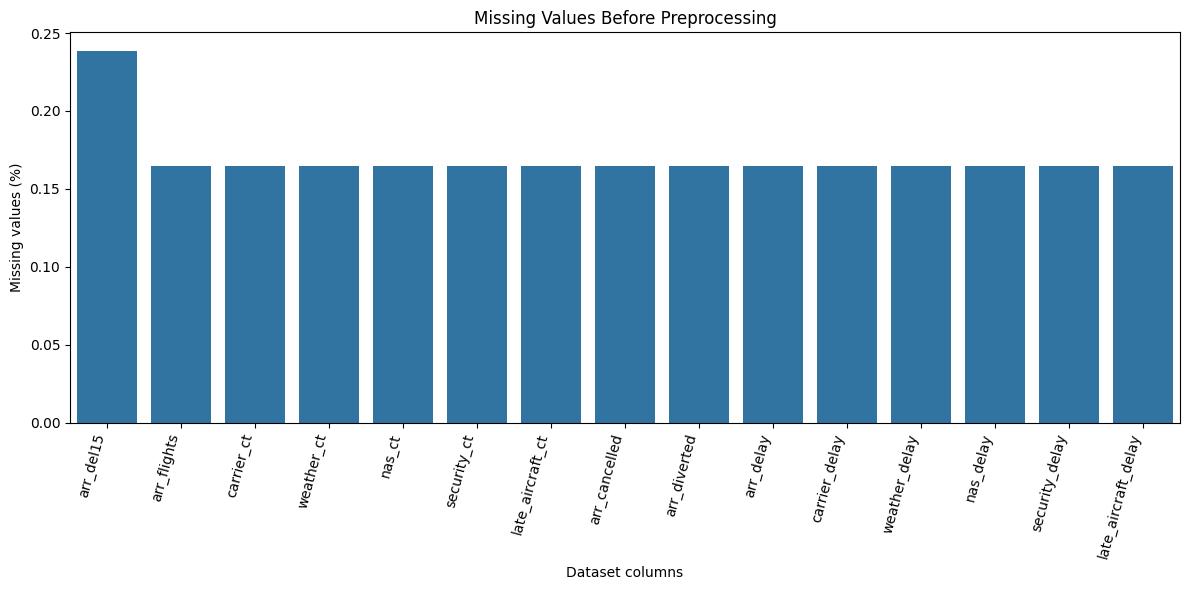


PREPROCESSING SUMMARY
{
    "original_rows": 398233,
    "original_columns": 21,
    "exact_duplicates_removed": 0,
    "duplicate_monthly_key_rows_for_review": 0,
    "rows_after_cleaning": 397576,
    "target_variable": "arr_delay",
    "input_features": [
        "year",
        "month_sin",
        "month_cos",
        "carrier",
        "airport",
        "lag1_arr_delay",
        "previous_3_periods_avg_delay",
        "lag1_arr_flights"
    ],
    "excluded_same_period_leakage_columns": [
        "arr_del15",
        "carrier_ct",
        "weather_ct",
        "nas_ct",
        "security_ct",
        "late_aircraft_ct",
        "carrier_delay",
        "weather_delay",
        "nas_delay",
        "security_delay",
        "late_aircraft_delay",
        "arr_cancelled",
        "arr_diverted",
        "arr_flights"
    ],
    "training_records": 299633,
    "testing_records": 97943,
    "chronological_split_date": "2020-10-01T00:00:00.000000000",
    "transformed_training_featu

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# PART D: DATA PREPARATION AND FEATURE ENGINEERING
# Flight Delay & Network Congestion Prediction Model
# Target: arr_delay (monthly accumulated arrival delay minutes)

# 1. IMPORT LIBRARIES
import os
import json
import zipfile
import warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression

warnings.filterwarnings("ignore")


# 2. CREATE NEW OUTPUT FOLDER
OUTPUT_DIR = "/content/Flight_Delay_Part_D"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output folder created:", OUTPUT_DIR)


# 3. LOAD EXISTING DATASET FROM COLAB
DATASET_PATH = "/content/Airline_Delay_Cause.csv"

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        "Airline_Delay_Cause.csv was not found in /content. "
        "Please check the uploaded file location."
    )

df = pd.read_csv(DATASET_PATH, low_memory=False)

print("\nOriginal dataset shape:", df.shape)
print("\nOriginal columns:")
print(df.columns.tolist())

# Standardise column names
df.columns = df.columns.str.strip().str.lower()

# Check required columns
required_columns = [
    "year", "month", "carrier", "airport", "arr_delay"
]

missing_required = [
    col for col in required_columns if col not in df.columns
]

if missing_required:
    raise ValueError(
        f"Required columns are missing: {missing_required}"
    )


# 4. INITIAL DATA QUALITY REPORT
original_shape = df.shape

missing_before = df.isnull().sum().reset_index()
missing_before.columns = ["column", "missing_count"]
missing_before["missing_percentage"] = (
    missing_before["missing_count"] / len(df) * 100
)

missing_before.to_csv(
    f"{OUTPUT_DIR}/missing_values_before.csv",
    index=False
)

print("\nMissing values before preprocessing:")
print(missing_before.to_string(index=False))


# 5. REMOVE EXACT DUPLICATES
exact_duplicates = df.duplicated().sum()

df = df.drop_duplicates().copy()

print("\nExact duplicate rows removed:", exact_duplicates)
print("Shape after exact duplicate removal:", df.shape)

# Check duplicate airline-airport-month keys
key_columns = ["year", "month", "carrier", "airport"]

duplicate_keys = df.duplicated(
    subset=key_columns, keep=False
).sum()

print(
    "Rows involved in duplicate airline-airport-month keys:",
    duplicate_keys
)

duplicate_key_report = (
    df[df.duplicated(subset=key_columns, keep=False)]
    .sort_values(key_columns)
)

duplicate_key_report.to_csv(
    f"{OUTPUT_DIR}/duplicate_monthly_keys_for_review.csv",
    index=False
)


# 6. CONVERT DATA TYPES
numeric_columns = [
    "year", "month", "arr_flights", "arr_del15",
    "carrier_ct", "weather_ct", "nas_ct",
    "security_ct", "late_aircraft_ct",
    "arr_cancelled", "arr_diverted", "arr_delay",
    "carrier_delay", "weather_delay", "nas_delay",
    "security_delay", "late_aircraft_delay"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

categorical_columns = ["carrier", "airport"]

for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)


# 7. HANDLE INVALID YEAR AND MONTH VALUES
df.loc[
    ~df["month"].between(1, 12), "month"
] = np.nan

df.loc[
    df["year"].isna() | (df["year"] <= 0), "year"
] = np.nan

df = df.dropna(
    subset=["year", "month", "carrier", "airport", "arr_delay"]
).copy()

df["year"] = df["year"].astype(int)
df["month"] = df["month"].astype(int)

print("\nShape after removing rows with missing target or identifiers:")
print(df.shape)


# 8. FEATURE ENGINEERING
df["period"] = pd.to_datetime(
    df["year"].astype(str)
    + "-"
    + df["month"].astype(str).str.zfill(2)
    + "-01"
)

# Cyclical month encoding
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

# Sort records chronologically
df = df.sort_values(
    ["carrier", "airport", "period"]
).reset_index(drop=True)

# Historical delay features
grouped = df.groupby(["carrier", "airport"], sort=False)

df["lag1_arr_delay"] = grouped["arr_delay"].shift(1)

df["previous_3_periods_avg_delay"] = (
    df.groupby(["carrier", "airport"], sort=False)["arr_delay"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=3, min_periods=1
        ).mean()
    )
)

# Previous available period's flight volume
if "arr_flights" in df.columns:
    df["lag1_arr_flights"] = (
        grouped["arr_flights"].shift(1)
    )

df.to_csv(
    f"{OUTPUT_DIR}/data_with_engineered_features.csv",
    index=False
)

print("\nFeature engineering completed.")


# 9. DEFINE TARGET AND INPUT FEATURES
TARGET = "arr_delay"

feature_columns = [
    "year",
    "month_sin",
    "month_cos",
    "carrier",
    "airport",
    "lag1_arr_delay",
    "previous_3_periods_avg_delay"
]

if "lag1_arr_flights" in df.columns:
    feature_columns.append("lag1_arr_flights")

X = df[feature_columns].copy()
y = df[TARGET].copy()

leakage_columns = [
    "arr_del15",
    "carrier_ct", "weather_ct", "nas_ct",
    "security_ct", "late_aircraft_ct",
    "carrier_delay", "weather_delay", "nas_delay",
    "security_delay", "late_aircraft_delay",
    "arr_cancelled", "arr_diverted", "arr_flights"
]

print("\nTarget variable:", TARGET)
print("Input features:", feature_columns)
print("Excluded same-period leakage fields:", leakage_columns)


# 10. CHRONOLOGICAL TRAIN-TEST SPLIT
unique_periods = np.sort(df["period"].unique())

if len(unique_periods) < 2:
    raise ValueError("Not enough unique months for a time-based split.")

split_position = int(len(unique_periods) * 0.80)
split_position = min(
    max(split_position, 1),
    len(unique_periods) - 1
)

split_date = unique_periods[split_position]

train_mask = df["period"] < split_date
test_mask = df["period"] >= split_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nChronological split date:", split_date)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print(
    "Training period:",
    df.loc[train_mask, "period"].min(),
    "to",
    df.loc[train_mask, "period"].max()
)

print(
    "Testing period:",
    df.loc[test_mask, "period"].min(),
    "to",
    df.loc[test_mask, "period"].max()
)


# 11. MISSING VALUE HANDLING, ENCODING AND SCALING
numeric_features = [
    col for col in feature_columns
    if col not in categorical_columns
]

categorical_features = categorical_columns

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing completed.")
print("Training transformed shape:", X_train_processed.shape)
print("Testing transformed shape:", X_test_processed.shape)


# 12. FEATURE SELECTION
number_of_features = min(30, X_train_processed.shape[1])

selector = SelectKBest(
    score_func=f_regression,
    k=number_of_features
)

X_train_selected = selector.fit_transform(
    X_train_processed, y_train
)

X_test_selected = selector.transform(X_test_processed)

all_feature_names = preprocessor.get_feature_names_out()

selected_feature_names = all_feature_names[
    selector.get_support()
]

print("\nFeature selection completed.")
print("Number of selected features:", len(selected_feature_names))

selected_features_df = pd.DataFrame({
    "selected_feature": selected_feature_names,
    "f_score": selector.scores_[selector.get_support()]
}).sort_values("f_score", ascending=False)

selected_features_df.to_csv(
    f"{OUTPUT_DIR}/selected_features.csv",
    index=False
)

print("\nSelected features:")
print(selected_features_df.to_string(index=False))


# 13. SAVE TRANSFORMED DATA
X_train_sparse = sp.csr_matrix(X_train_selected)
X_test_sparse = sp.csr_matrix(X_test_selected)

sp.save_npz(
    f"{OUTPUT_DIR}/X_train_processed.npz",
    X_train_sparse
)

sp.save_npz(
    f"{OUTPUT_DIR}/X_test_processed.npz",
    X_test_sparse
)

y_train.to_csv(
    f"{OUTPUT_DIR}/y_train.csv",
    index=False
)

y_test.to_csv(
    f"{OUTPUT_DIR}/y_test.csv",
    index=False
)

pd.DataFrame({
    "feature_name": selected_feature_names
}).to_csv(
    f"{OUTPUT_DIR}/processed_feature_names.csv",
    index=False
)


# 14. SAVE CLEANED DATASET
df.to_csv(
    f"{OUTPUT_DIR}/cleaned_engineered_dataset.csv",
    index=False
)


# 15. MISSING VALUE REPORT AFTER CLEANING
missing_after = df.isnull().sum().reset_index()
missing_after.columns = ["column", "missing_count"]

missing_after["missing_percentage"] = (
    missing_after["missing_count"] / len(df) * 100
)

missing_after.to_csv(
    f"{OUTPUT_DIR}/missing_values_after.csv",
    index=False
)


# 16. VISUALISE MISSING VALUES BEFORE PREPROCESSING
plt.figure(figsize=(12, 6))

missing_plot = (
    missing_before[missing_before["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

if not missing_plot.empty:
    sns.barplot(
        data=missing_plot,
        x="column",
        y="missing_percentage"
    )

    plt.xticks(rotation=75, ha="right")
    plt.ylabel("Missing values (%)")
    plt.xlabel("Dataset columns")
    plt.title("Missing Values Before Preprocessing")
    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/missing_values_chart.png",
        dpi=300
    )

    plt.show()
else:
    print("No missing values found.")


# 17. SAVE PREPROCESSING OBJECTS
joblib.dump(
    preprocessor,
    f"{OUTPUT_DIR}/preprocessor.joblib"
)

joblib.dump(
    selector,
    f"{OUTPUT_DIR}/feature_selector.joblib"
)


# 18. SAVE PREPROCESSING SUMMARY
summary = {
    "original_rows": int(original_shape[0]),
    "original_columns": int(original_shape[1]),
    "exact_duplicates_removed": int(exact_duplicates),
    "duplicate_monthly_key_rows_for_review": int(duplicate_keys),
    "rows_after_cleaning": int(len(df)),
    "target_variable": TARGET,
    "input_features": feature_columns,
    "excluded_same_period_leakage_columns": leakage_columns,
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test)),
    "chronological_split_date": str(split_date),
    "transformed_training_features": int(X_train_processed.shape[1]),
    "selected_features": int(len(selected_feature_names)),
    "pca_applied": False,
    "smote_applied": False
}

with open(
    f"{OUTPUT_DIR}/preprocessing_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\nPREPROCESSING SUMMARY")
print(json.dumps(summary, indent=4))


# 19. CREATE ZIP FILE INSIDE THE NEW OUTPUT FOLDER
zip_path = (
    "/content/Flight_Delay_Part_D/"
    "Flight_Delay_Part_D_Outputs.zip"
)

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:

            full_path = os.path.join(root, filename)

            # Do not include the ZIP file inside itself
            if full_path == zip_path:
                continue

            relative_path = os.path.relpath(
                full_path, OUTPUT_DIR
            )

            zipf.write(full_path, relative_path)

print("\n======================================")
print("PREPROCESSING COMPLETED SUCCESSFULLY")
print("======================================")

print("Output folder:", OUTPUT_DIR)
print("ZIP file:", zip_path)

# 20. DOWNLOAD ZIP FILE
files.download(zip_path)


Libraries imported successfully.

Part D processed data loaded successfully.
Training feature shape: (299633, 30)
Testing feature shape: (97943, 30)
Training target shape: (299633,)
Testing target shape: (97943,)
Number of selected features: 30

Data validation and preparation completed.
Training records: 299633
Testing records: 97943
Selected features: 30
Training matrix shape: (299633, 30)
Testing matrix shape: (97943, 30)

Data validation completed.
Training records: 299633
Testing records: 97943
Selected features: 30

Feature conversion completed.
Training matrix shape: (299633, 30)
Testing matrix shape: (97943, 30)

Three regression models created successfully.

Training: Linear Regression
Model training completed.
MAE: 1523.0839
MSE: 29293683.193
RMSE: 5412.3639
R2: 0.8372

Training: Random Forest
Model training completed.
MAE: 1498.7133
MSE: 32056035.7201
RMSE: 5661.805
R2: 0.8218

Training: Histogram Gradient Boosting
Model training completed.
MAE: 1524.1773
MSE: 38449352.2708


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,1523.083857,2.929368e+07,5412.363919,0.837161
1,Random Forest,1498.713333,3.205604e+07,5661.804988,0.821805
2,Histogram Gradient Boosting,1524.177326,3.844935e+07,6200.754170,0.786266



Best model based on RMSE: Linear Regression

Test set predictions saved.


,test_record_index,actual_arr_delay,linear_regression_prediction,random_forest_prediction,histogram_gradient_boosting_prediction
0,0,16.0,228.762695,365.570301,372.926611
1,1,69.0,14.176758,193.066248,278.720615
2,2,89.0,85.171631,230.327489,278.720615
3,3,32.0,134.763184,270.527193,327.068502
4,4,688.0,343.062500,391.203138,621.365731


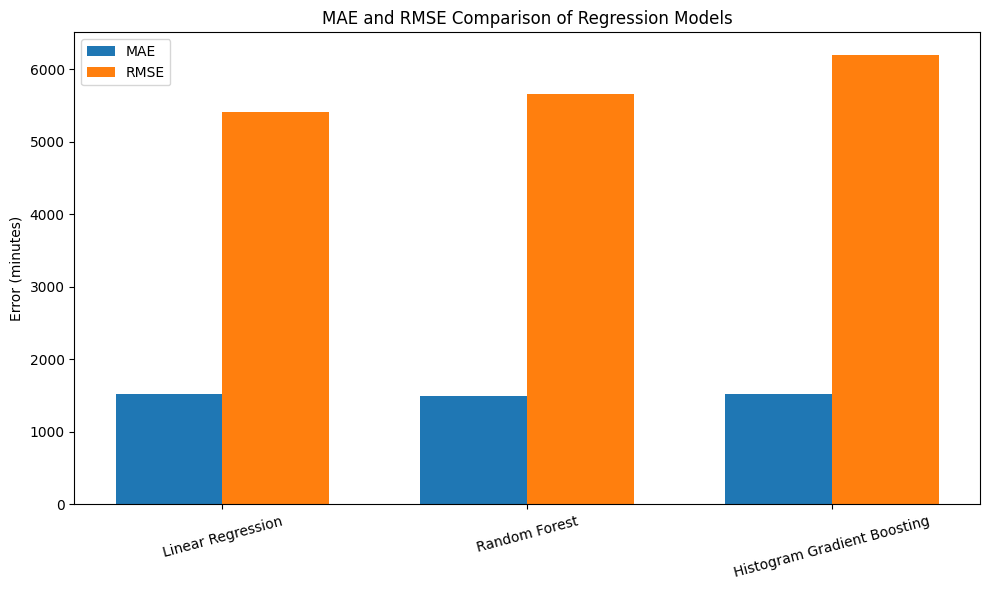

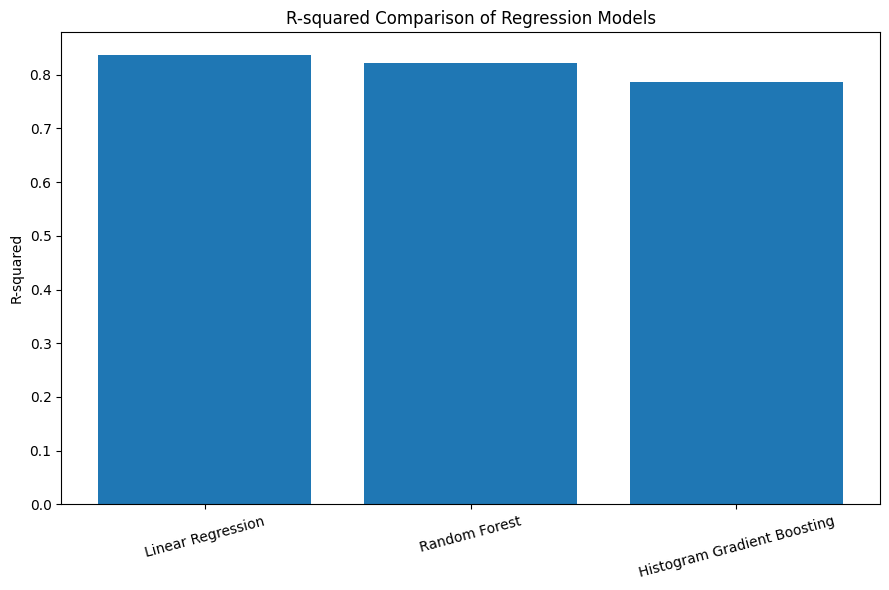

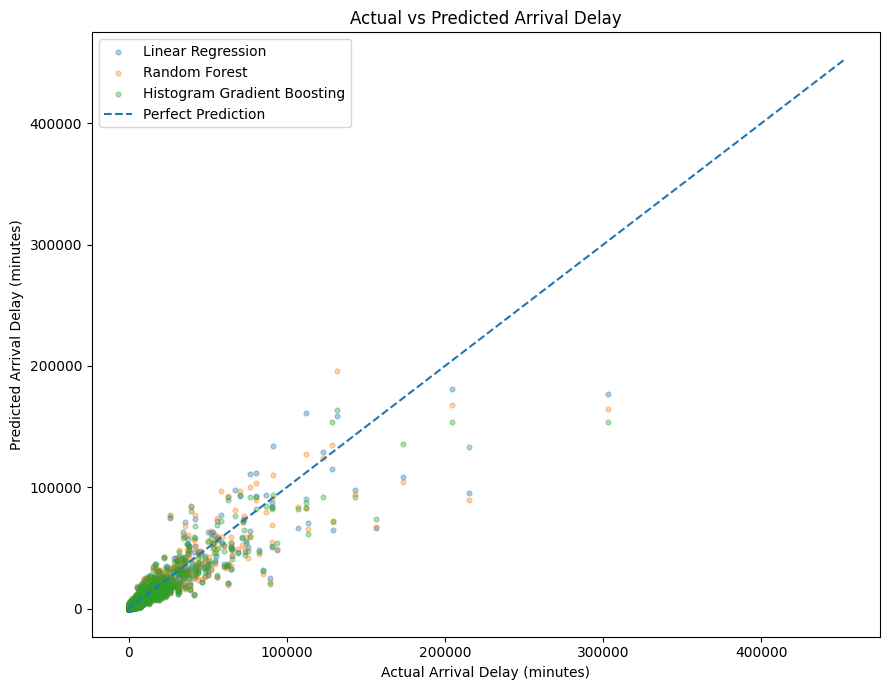


Trained models saved successfully.

All Part E outputs saved successfully.

ZIP file created: Part_E_Regression_Results.zip

Part E modelling process completed!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# part E
# Flight Delay & Network Congestion Prediction Model
# Dataset: Part D Processed Data
# Target: arr_delay

# Models:
# 1. Linear Regression
# 2. Random Forest Regressor
# 3. Histogram-Based Gradient Boosting Regressor


import os
import zipfile
import warnings
import joblib

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully.")

# 2. LOAD PART D PROCESSED DATA
# Load processed training and testing feature matrices
X_train_sparse = sp.load_npz(
    "X_train_processed.npz"
)

X_test_sparse = sp.load_npz(
    "X_test_processed.npz"
)

# Load target variables
y_train_df = pd.read_csv("y_train.csv")
y_test_df = pd.read_csv("y_test.csv")
# Identify target column
target_column = (
    "arr_delay"
    if "arr_delay" in y_train_df.columns
    else y_train_df.columns[0]
)
y_train = pd.to_numeric(
    y_train_df[target_column],
    errors="coerce"
).to_numpy()
y_test = pd.to_numeric(
    y_test_df[target_column],
    errors="coerce"
).to_numpy()
# Load selected feature names
feature_names_df = pd.read_csv(
    "processed_feature_names.csv"
)
feature_names = feature_names_df.iloc[:, 0].tolist()

print("\nPart D processed data loaded successfully.")

print("Training feature shape:", X_train_sparse.shape)
print("Testing feature shape:", X_test_sparse.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("Number of selected features:", len(feature_names))


# 3. VALIDATE AND PREPARE PROCESSED DATA
# Check feature dimensions
if X_train_sparse.shape[1] != X_test_sparse.shape[1]:
    raise ValueError(
        "Training and testing feature dimensions do not match."
    )

if X_train_sparse.shape[1] != len(feature_names):
    raise ValueError(
        "Feature names and feature matrix dimensions do not match."
    )

# Check training and testing record counts
if X_train_sparse.shape[0] != len(y_train):
    raise ValueError(
        "Training feature and target record counts do not match."
    )

if X_test_sparse.shape[0] != len(y_test):
    raise ValueError(
        "Testing feature and target record counts do not match."
    )

# Check target values
if not np.isfinite(y_train).all():
    raise ValueError(
        "Training target contains missing or infinite values."
    )

if not np.isfinite(y_test).all():
    raise ValueError(
        "Testing target contains missing or infinite values."
    )

# Convert sparse matrices to dense arrays
# Required by HistGradientBoostingRegressor.
X_train = X_train_sparse.toarray().astype(np.float32)
X_test = X_test_sparse.toarray().astype(np.float32)

print("\nData validation and preparation completed.")

print("Training records:", len(y_train))
print("Testing records:", len(y_test))
print("Selected features:", len(feature_names))
print("Training matrix shape:", X_train.shape)
print("Testing matrix shape:", X_test.shape)

# 4. VALIDATE PROCESSED DATA

if X_train_sparse.shape[1] != X_test_sparse.shape[1]:
    raise ValueError(
        "Training and testing feature dimensions do not match."
    )

if X_train_sparse.shape[1] != len(feature_names):
    raise ValueError(
        "Feature matrix dimensions do not match selected feature names."
    )

if X_train_sparse.shape[0] != len(y_train):
    raise ValueError(
        "Training feature and target record counts do not match."
    )

if X_test_sparse.shape[0] != len(y_test):
    raise ValueError(
        "Testing feature and target record counts do not match."
    )

if not np.isfinite(y_train).all():
    raise ValueError(
        "Training target contains missing or infinite values."
    )

if not np.isfinite(y_test).all():
    raise ValueError(
        "Testing target contains missing or infinite values."
    )

print("\nData validation completed.")

print("Training records:", len(y_train))
print("Testing records:", len(y_test))
print("Selected features:", len(feature_names))


# 5. CONVERT SPARSE MATRICES INTO DENSE ARRAYS

# The processed matrices contain only 30 selected features.
# Convert them to dense arrays for model training.
#
# HistGradientBoostingRegressor requires dense input.
# Using dense arrays for all three models also keeps the
# model input format consistent.

X_train = X_train_sparse.toarray().astype(
    np.float32
)

X_test = X_test_sparse.toarray().astype(
    np.float32
)

print("\nFeature conversion completed.")

print("Training matrix shape:", X_train.shape)
print("Testing matrix shape:", X_test.shape)


# 6. DEFINE THREE REGRESSION MODELS

# MODEL 1: LINEAR REGRESSION

linear_model = LinearRegression(
    n_jobs=-1
)


# MODEL 2: RANDOM FOREST REGRESSOR

random_forest_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=18,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features=0.7,
    max_samples=0.8,
    bootstrap=True,
    n_jobs=-1,
    random_state=RANDOM_STATE
)


# MODEL 3: HISTOGRAM-BASED GRADIENT BOOSTING REGRESSOR

hist_gradient_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    early_stopping=True,
    random_state=RANDOM_STATE
)


# Store all models in a dictionary

models = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model,
    "Histogram Gradient Boosting": hist_gradient_model
}

print("\nThree regression models created successfully.")


# 7. TRAIN MODELS AND GENERATE PREDICTIONS
results = []
predictions = {}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    # Train the model using Part D training data
    model.fit(
        X_train,
        y_train
    )

    print("Model training completed.")

    # Generate predictions using Part D testing data
    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred

    # Calculate evaluation metrics
    mae = mean_absolute_error(
        y_test,
        y_pred
    )
    mse = mean_squared_error(
        y_test,
        y_pred
    )
    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        y_pred
    )
    # Store evaluation results
    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("R2:", round(r2, 4))

print("\nAll models trained and evaluated successfully.")


# 8. COMPARE MODEL PERFORMANCE

results_df = pd.DataFrame(results)

# Sort models according to RMSE
# Lower RMSE indicates smaller prediction errors.

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("\nMODEL EVALUATION RESULTS")

display(results_df)

# Identify the best model based on RMSE

best_model_name = results_df.loc[0, "Model"]

print("\nBest model based on RMSE:", best_model_name)

# Save evaluation results

results_df.to_csv(
    "model_evaluation_results.csv",
    index=False
)


# 9. CREATE TEST SET PREDICTION RESULTS

# The saved Part D matrices do not contain the original period, carrier and airport columns.
# Therefore, predictions are matched using test record index.

prediction_df = pd.DataFrame({
    "test_record_index": np.arange(len(y_test)),
    "actual_arr_delay": y_test
})

# Add predictions from each model

for model_name, y_pred in predictions.items():

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
    )

    prediction_df[
        f"{safe_name}_prediction"
    ] = y_pred

# Save prediction results

prediction_df.to_csv(
    "test_set_predictions.csv",
    index=False
)

print("\nTest set predictions saved.")

display(prediction_df.head())


# 10. VISUALISE MODEL PERFORMANCE

# 10.1 MAE AND RMSE COMPARISON

plt.figure(figsize=(10, 6))

x = np.arange(len(results_df))
width = 0.35

plt.bar(
    x - width / 2,
    results_df["MAE"],
    width,
    label="MAE"
)

plt.bar(
    x + width / 2,
    results_df["RMSE"],
    width,
    label="RMSE"
)

plt.xticks(
    x,
    results_df["Model"],
    rotation=15
)

plt.ylabel("Error (minutes)")

plt.title(
    "MAE and RMSE Comparison of Regression Models"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "mae_rmse_comparison.png",
    dpi=300
)

plt.show()


# 10.2 R-SQUARED COMPARISON

plt.figure(figsize=(9, 6))

plt.bar(
    results_df["Model"],
    results_df["R2"]
)

plt.ylabel("R-squared")

plt.title(
    "R-squared Comparison of Regression Models"
)

plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "r2_comparison.png",
    dpi=300
)

plt.show()


# 10.3 ACTUAL VS PREDICTED VALUES

# Use a sample of up to 5,000 testing records for clearer visualisation.
# Evaluation metrics still use the complete testing dataset.

sample_size = min(
    5000,
    len(y_test)
)

rng = np.random.default_rng(
    RANDOM_STATE
)

sample_indices = np.sort(
    rng.choice(
        len(y_test),
        size=sample_size,
        replace=False
    )
)

actual_sample = y_test[sample_indices]

plt.figure(figsize=(9, 7))

for model_name, y_pred in predictions.items():

    plt.scatter(
        actual_sample,
        y_pred[sample_indices],
        alpha=0.35,
        s=12,
        label=model_name
    )

# Reference line for perfect predictions

min_value = min(
    actual_sample.min(),
    min(np.min(pred) for pred in predictions.values())
)

max_value = max(
    actual_sample.max(),
    max(np.max(pred) for pred in predictions.values())
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel(
    "Actual Arrival Delay (minutes)"
)

plt.ylabel(
    "Predicted Arrival Delay (minutes)"
)

plt.title(
    "Actual vs Predicted Arrival Delay"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "actual_vs_predicted.png",
    dpi=300
)

plt.show()


# 11. SAVE TRAINED MODELS

output_folder = "Part_E_Regression_Results"

os.makedirs(
    output_folder,
    exist_ok=True
)

# Save each trained model

for model_name, model in models.items():

    filename = (
        model_name.lower()
        .replace(" ", "_")
        + ".pkl"
    )

    joblib.dump(
        model,
        os.path.join(
            output_folder,
            filename
        )
    )

print("\nTrained models saved successfully.")


# 12. SAVE RESULTS AND SELECTED FEATURE NAMES

# Save evaluation results

results_df.to_csv(
    os.path.join(
        output_folder,
        "model_evaluation_results.csv"
    ),
    index=False
)

# Save test predictions

prediction_df.to_csv(
    os.path.join(
        output_folder,
        "test_set_predictions.csv"
    ),
    index=False
)

# Save selected feature names

feature_names_df.to_csv(
    os.path.join(
        output_folder,
        "processed_feature_names.csv"
    ),
    index=False
)

# Save charts

chart_files = [
    "mae_rmse_comparison.png",
    "r2_comparison.png",
    "actual_vs_predicted.png"
]

for filename in chart_files:

    if os.path.exists(filename):

        os.replace(
            filename,
            os.path.join(
                output_folder,
                filename
            )
        )


# 13. SAVE MODEL SUMMARY

with open(
    os.path.join(
        output_folder,
        "model_summary.txt"
    ),
    "w"
) as file:

    file.write(
        "PART E: REGRESSION MODEL EVALUATION\n"
    )

    file.write("=" * 50 + "\n\n")

    file.write(
        "Target variable: arr_delay\n"
    )

    file.write(
        "Training records: "
        + str(len(y_train))
        + "\n"
    )

    file.write(
        "Testing records: "
        + str(len(y_test))
        + "\n"
    )

    file.write(
        "Number of selected features: "
        + str(len(feature_names))
        + "\n\n"
    )

    file.write(
        "Models evaluated:\n"
    )

    for model_name in models.keys():

        file.write(
            "- " + model_name + "\n"
        )

    file.write(
        "\nModel Evaluation Results:\n"
    )

    file.write(
        results_df.to_string(index=False)
    )

    file.write(
        "\n\nBest model based on RMSE: "
        + best_model_name
    )

print("\nAll Part E outputs saved successfully.")


# 14. COMPRESS OUTPUTS INTO A ZIP FILE

zip_filename = "Part_E_Regression_Results.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for root, dirs, filenames in os.walk(
        output_folder
    ):

        for filename in filenames:

            file_path = os.path.join(
                root,
                filename
            )

            zip_file.write(
                file_path,
                arcname=os.path.relpath(
                    file_path,
                    output_folder
                )
            )

print("\nZIP file created:", zip_filename)


# 15. DOWNLOAD PART E RESULTS
print("\nPart E modelling process completed!")

files.download(zip_filename)


Libraries imported successfully.
Please upload your files1116.zip file.


Saving files1116.zip to files1116.zip
ZIP file extracted successfully.
All required files located.

DATA LOADED SUCCESSFULLY
Training features: (299633, 30)
Testing features: (97943, 30)
Training targets: (299633,)
Testing targets: (97943,)
Selected features: 30

Data validation completed successfully.

TRAINING BASELINE MODELS

Training Linear Regression...
Results: {'MAE': 1523.08385690928, 'MSE': 29293683.193033133, 'RMSE': np.float64(5412.363919123799), 'R2': 0.8371608347955142}

Training Random Forest...
Results: {'MAE': 1538.673784036806, 'MSE': 33091237.55895576, 'RMSE': np.float64(5752.498375397924), 'R2': 0.8160508030289195}

Training Histogram Gradient Boosting...
Results: {'MAE': 1523.6284548289116, 'MSE': 38425337.635708146, 'RMSE': np.float64(6198.8174384884205), 'R2': 0.7863993454811666}

BASELINE RESULTS


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,1523.083857,2.929368e+07,5412.363919,0.837161
1,Random Forest,1538.673784,3.309124e+07,5752.498375,0.816051
2,Histogram Gradient Boosting,1523.628455,3.842534e+07,6198.817438,0.786399



Cross-validation prepared.
Tuning sample size: 50000
Cross-validation folds: 3

RANDOM FOREST OPTIMISATION
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best Random Forest Parameters:
{'n_estimators': 350, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': 40}
Best Cross-Validation RMSE: 5053.712009761407

LINEAR REGRESSION OPTIMISATION
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Best Linear Regression Parameters:
{'fit_intercept': True, 'positive': False}
Best Cross-Validation RMSE: 4902.558136546569

HISTOGRAM GRADIENT BOOSTING OPTIMISATION
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best Histogram Gradient Boosting Parameters:
{'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 200, 'max_depth': 20, 'learning_rate': 0.1, 'l2_regularization': 0.1}
Best Cross-Validation RMSE: 5066.207771827951

OPTIMISED MODEL RESULTS


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,1523.083857,2.929368e+07,5412.363919,0.837161
1,Random Forest,1506.495815,3.191795e+07,5649.597489,0.822573
2,Histogram Gradient Boosting,1524.496925,3.811814e+07,6173.989158,0.788107



BASELINE VS OPTIMISED COMPARISON


,Model,Baseline MAE,Optimised MAE,Baseline RMSE,Optimised RMSE,Baseline R2,Optimised R2,RMSE Improvement (%),R2 Improvement
0,Linear Regression,1523.083857,1523.083857,5412.363919,5412.363919,0.837161,0.837161,0.000000,0.000000
1,Random Forest,1538.673784,1506.495815,5752.498375,5649.597489,0.816051,0.822573,1.788803,0.006522
2,Histogram Gradient Boosting,1523.628455,1524.496925,6198.817438,6173.989158,0.786399,0.788107,0.400533,0.001708



Optimised models saved successfully.


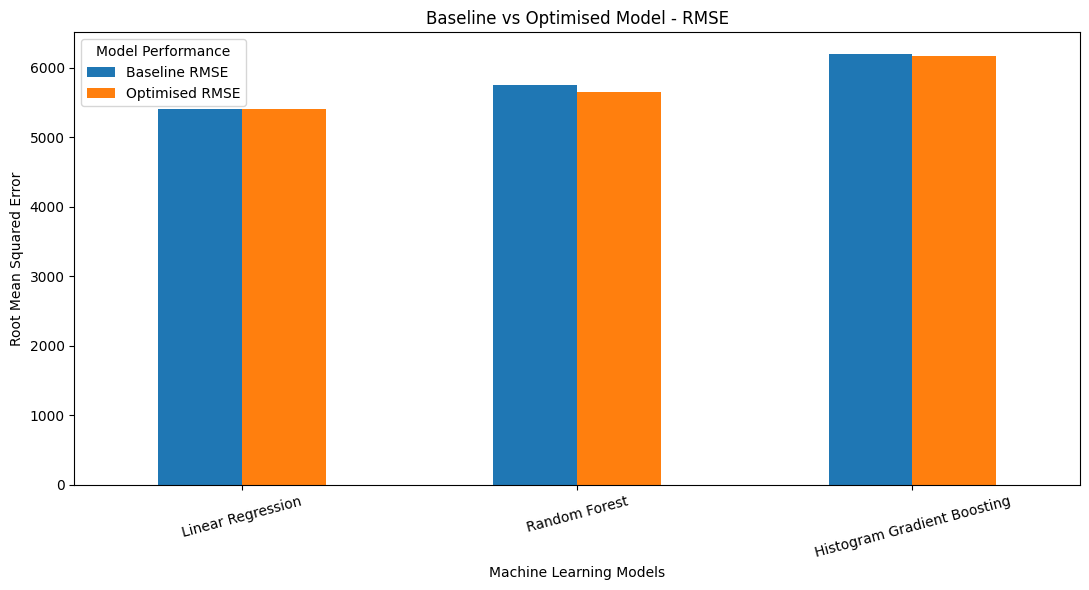

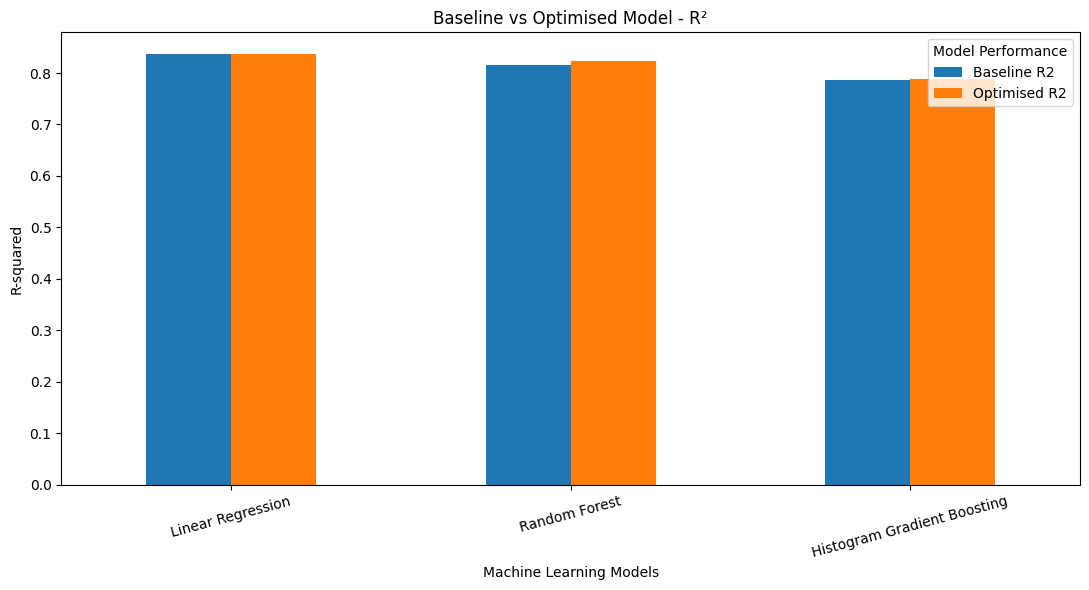


PART F - HYPERPARAMETER OPTIMISATION COMPLETED

BEST HYPERPARAMETERS

 Random Forest
{'n_estimators': 350, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': 40}

 Linear Regression
{'fit_intercept': True, 'positive': False}

 Histogram Gradient Boosting
{'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 200, 'max_depth': 20, 'learning_rate': 0.1, 'l2_regularization': 0.1}

FINAL PERFORMANCE COMPARISON


,Model,Baseline MAE,Optimised MAE,Baseline RMSE,Optimised RMSE,Baseline R2,Optimised R2,RMSE Improvement (%),R2 Improvement
0,Linear Regression,1523.083857,1523.083857,5412.363919,5412.363919,0.837161,0.837161,0.000000,0.000000
1,Random Forest,1538.673784,1506.495815,5752.498375,5649.597489,0.816051,0.822573,1.788803,0.006522
2,Histogram Gradient Boosting,1523.628455,1524.496925,6198.817438,6173.989158,0.786399,0.788107,0.400533,0.001708



All Part F results saved.
Output folder: /content/Part_F_Hyperparameter_Optimisation
ZIP file: /content/Part_F_Hyperparameter_Optimisation.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Part F output ZIP is ready for download.


In [ ]:
# part f
# Airline On-Time Statistics and Delay Causes Dataset
#
# Models:
# 1. Random Forest Regressor
# 2. Linear Regression
# 3. Histogram Gradient Boosting Regressor
#
# Techniques:
# 1. Randomized Search + 3-Fold Cross Validation
# 2. Grid Search + 3-Fold Cross Validation
#
# Primary optimisation metric: RMSE

import os
import glob
import json
import zipfile
import shutil
import warnings
import joblib
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.base import clone
from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
    GridSearchCV,
    train_test_split
)

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

OUTPUT_DIR = "/content/Part_F_Hyperparameter_Optimisation"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries imported successfully.")


# 2. UPLOAD AND EXTRACT EXISTING ZIP FILE

print("Please upload your files1116.zip file.")

uploaded = files.upload()

zip_files = [
    filename for filename in uploaded.keys()
    if filename.lower().endswith(".zip")
]

if not zip_files:
    raise FileNotFoundError(
        "Please upload the ZIP file containing Part D and Part E files."
    )

ZIP_PATH = "/content/" + zip_files[0]

EXTRACT_DIR = "/content/Part_F_Input"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("ZIP file extracted successfully.")


# 3. LOCATE REQUIRED FILES

def locate_file(filename):

    matches = glob.glob(
        os.path.join(EXTRACT_DIR, "**", filename),
        recursive=True
    )

    if not matches:
        raise FileNotFoundError(
            f"Required file not found: {filename}"
        )

    return matches[0]


X_TRAIN_PATH = locate_file("X_train_processed.npz")
X_TEST_PATH = locate_file("X_test_processed.npz")

Y_TRAIN_PATH = locate_file("y_train.csv")
Y_TEST_PATH = locate_file("y_test.csv")

FEATURE_PATH = locate_file("processed_feature_names.csv")

print("All required files located.")


# 4. LOAD PROCESSED TRAINING AND TESTING DATA

X_train_sparse = sp.load_npz(X_TRAIN_PATH)
X_test_sparse = sp.load_npz(X_TEST_PATH)

y_train = pd.read_csv(Y_TRAIN_PATH).iloc[:, 0].to_numpy()
y_test = pd.read_csv(Y_TEST_PATH).iloc[:, 0].to_numpy()

feature_names = pd.read_csv(
    FEATURE_PATH
).iloc[:, 0].tolist()

# Convert sparse matrices into dense arrays.
# Required by Histogram Gradient Boosting.

X_train = X_train_sparse.toarray().astype(np.float32)
X_test = X_test_sparse.toarray().astype(np.float32)

print("\nDATA LOADED SUCCESSFULLY")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print("Selected features:", len(feature_names))


# 5. VALIDATE DATA

assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)

assert X_train.shape[1] == X_test.shape[1]
assert X_train.shape[1] == len(feature_names)

assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()

assert np.isfinite(y_train).all()
assert np.isfinite(y_test).all()

print("\nData validation completed successfully.")


# 6. DEFINE EVALUATION FUNCTION

def evaluate_model(model, X, y):

    predictions = model.predict(X)

    mae = mean_absolute_error(y, predictions)

    mse = mean_squared_error(y, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y, predictions)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }, predictions


# 7. DEFINE BASELINE MODELS

baseline_models = {

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Histogram Gradient Boosting":
        HistGradientBoostingRegressor(
            random_state=RANDOM_STATE
        )
}


# 8. TRAIN AND EVALUATE BASELINE MODELS

baseline_results = []

baseline_predictions = {}

baseline_fitted_models = {}

print("\nTRAINING BASELINE MODELS")

for name, model in baseline_models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    metrics, predictions = evaluate_model(
        model,
        X_test,
        y_test
    )

    baseline_results.append({
        "Model": name,
        **metrics
    })

    baseline_predictions[name] = predictions

    baseline_fitted_models[name] = model

    print("Results:", metrics)


baseline_df = pd.DataFrame(baseline_results)

baseline_df.to_csv(
    f"{OUTPUT_DIR}/baseline_results.csv",
    index=False
)

print("\nBASELINE RESULTS")

display(baseline_df)


# 9. PREPARE CROSS-VALIDATION DATA

# Use a reproducible random subset for hyperparameter searching to reduce computational time.

TUNING_SAMPLE_SIZE = min(50000, len(y_train))

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=TUNING_SAMPLE_SIZE,
    random_state=RANDOM_STATE
)

# Three-fold shuffled cross-validation.

cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("\nCross-validation prepared.")

print("Tuning sample size:", len(y_tune))
print("Cross-validation folds:", 3)


# 10. RANDOM FOREST HYPERPARAMETER OPTIMISATION

print("\n" + "=" * 60)
print("RANDOM FOREST OPTIMISATION")
print("=" * 60)

rf_model = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_parameters = {

    "n_estimators": [150, 250, 350],

    "max_depth": [None, 20, 40],

    "min_samples_split": [2, 5, 10],

    "min_samples_leaf": [1, 2, 4],

    "max_features": [0.7, 1.0]

}

rf_search = RandomizedSearchCV(

    estimator=rf_model,

    param_distributions=rf_parameters,

    n_iter=8,

    scoring="neg_root_mean_squared_error",

    cv=cv,

    random_state=RANDOM_STATE,

    n_jobs=-1,

    verbose=2,

    refit=True

)

rf_search.fit(X_tune, y_tune)

print("\nBest Random Forest Parameters:")

print(rf_search.best_params_)

print(
    "Best Cross-Validation RMSE:",
    -rf_search.best_score_
)

# Refit best configuration using the complete training set.

best_rf = clone(rf_search.best_estimator_)

best_rf.set_params(n_jobs=-1)

best_rf.fit(X_train, y_train)

rf_metrics, rf_predictions = evaluate_model(
    best_rf,
    X_test,
    y_test
)


# 11. LINEAR REGRESSION HYPERPARAMETER OPTIMISATION

print("\n" + "=" * 60)
print("LINEAR REGRESSION OPTIMISATION")
print("=" * 60)

lr_model = LinearRegression()

lr_parameters = {

    "fit_intercept": [True, False],

    "positive": [True, False]

}

lr_search = GridSearchCV(

    estimator=lr_model,

    param_grid=lr_parameters,

    scoring="neg_root_mean_squared_error",

    cv=cv,

    n_jobs=-1,

    verbose=2,

    refit=True

)

lr_search.fit(X_tune, y_tune)

print("\nBest Linear Regression Parameters:")

print(lr_search.best_params_)

print(
    "Best Cross-Validation RMSE:",
    -lr_search.best_score_
)

# Refit best configuration using complete training data.

best_lr = clone(lr_search.best_estimator_)

best_lr.fit(X_train, y_train)

lr_metrics, lr_predictions = evaluate_model(
    best_lr,
    X_test,
    y_test
)


# 12. HISTOGRAM GRADIENT BOOSTING OPTIMISATION

print("\n" + "=" * 60)
print("HISTOGRAM GRADIENT BOOSTING OPTIMISATION")
print("=" * 60)

hgb_model = HistGradientBoostingRegressor(
    random_state=RANDOM_STATE
)

hgb_parameters = {

    "learning_rate": [0.03, 0.05, 0.1],

    "max_iter": [100, 200, 300],

    "max_leaf_nodes": [15, 31, 50],

    "max_depth": [None, 10, 20],

    "min_samples_leaf": [20, 30, 50],

    "l2_regularization": [0.0, 0.1, 1.0]

}

hgb_search = RandomizedSearchCV(

    estimator=hgb_model,

    param_distributions=hgb_parameters,

    n_iter=8,

    scoring="neg_root_mean_squared_error",

    cv=cv,

    random_state=RANDOM_STATE,

    n_jobs=-1,

    verbose=2,

    refit=True

)

hgb_search.fit(X_tune, y_tune)

print("\nBest Histogram Gradient Boosting Parameters:")

print(hgb_search.best_params_)

print(
    "Best Cross-Validation RMSE:",
    -hgb_search.best_score_
)

# Refit best configuration using complete training data.

best_hgb = clone(hgb_search.best_estimator_)

best_hgb.fit(X_train, y_train)

hgb_metrics, hgb_predictions = evaluate_model(
    best_hgb,
    X_test,
    y_test
)


# 13. COMPILE OPTIMISED RESULTS

optimised_models = {

    "Linear Regression": best_lr,

    "Random Forest": best_rf,

    "Histogram Gradient Boosting": best_hgb

}

optimised_predictions = {

    "Linear Regression": lr_predictions,

    "Random Forest": rf_predictions,

    "Histogram Gradient Boosting": hgb_predictions

}

optimised_metrics = {

    "Linear Regression": lr_metrics,

    "Random Forest": rf_metrics,

    "Histogram Gradient Boosting": hgb_metrics

}

optimised_results = []

for name, metrics in optimised_metrics.items():

    optimised_results.append({

        "Model": name,

        **metrics

    })

optimised_df = pd.DataFrame(optimised_results)

optimised_df.to_csv(
    f"{OUTPUT_DIR}/optimised_results.csv",
    index=False
)

print("\nOPTIMISED MODEL RESULTS")

display(optimised_df)


# 14. COMPARE BASELINE AND OPTIMISED RESULTS

comparison_rows = []

for name in baseline_models.keys():

    base = baseline_df[
        baseline_df["Model"] == name
    ].iloc[0]

    opt = optimised_df[
        optimised_df["Model"] == name
    ].iloc[0]

    comparison_rows.append({

        "Model": name,

        "Baseline MAE": base["MAE"],

        "Optimised MAE": opt["MAE"],

        "Baseline RMSE": base["RMSE"],

        "Optimised RMSE": opt["RMSE"],

        "Baseline R2": base["R2"],

        "Optimised R2": opt["R2"],

        "RMSE Improvement (%)":
            ((base["RMSE"] - opt["RMSE"])
             / base["RMSE"]) * 100,

        "R2 Improvement":
            opt["R2"] - base["R2"]

    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df.to_csv(
    f"{OUTPUT_DIR}/baseline_vs_optimised_comparison.csv",
    index=False
)

print("\nBASELINE VS OPTIMISED COMPARISON")

display(comparison_df)


# 15. SAVE BEST HYPERPARAMETERS

best_parameters = {

    "Random Forest": {
        "best_parameters": rf_search.best_params_,
        "best_cv_rmse": float(-rf_search.best_score_),
        "search_method": "RandomizedSearchCV",
        "n_iter": 8,
        "cv_folds": 3
    },

    "Linear Regression": {
        "best_parameters": lr_search.best_params_,
        "best_cv_rmse": float(-lr_search.best_score_),
        "search_method": "GridSearchCV",
        "parameter_combinations": 4,
        "cv_folds": 3
    },

    "Histogram Gradient Boosting": {
        "best_parameters": hgb_search.best_params_,
        "best_cv_rmse": float(-hgb_search.best_score_),
        "search_method": "RandomizedSearchCV",
        "n_iter": 8,
        "cv_folds": 3
    }

}

with open(
    f"{OUTPUT_DIR}/best_hyperparameters.json",
    "w"
) as file:

    json.dump(
        best_parameters,
        file,
        indent=4
    )


# 16. SAVE CROSS-VALIDATION RESULTS

def save_cv_results(search, filename):

    results = pd.DataFrame(search.cv_results_)

    results["CV_RMSE"] = -results["mean_test_score"]

    results["CV_RMSE_STD"] = results["std_test_score"]

    results.to_csv(
        f"{OUTPUT_DIR}/{filename}",
        index=False
    )


save_cv_results(
    rf_search,
    "random_forest_cv_results.csv"
)

save_cv_results(
    lr_search,
    "linear_regression_cv_results.csv"
)

save_cv_results(
    hgb_search,
    "histogram_gradient_boosting_cv_results.csv"
)


# 17. SAVE OPTIMISED MODELS

joblib.dump(
    best_rf,
    f"{OUTPUT_DIR}/optimised_random_forest.pkl"
)

joblib.dump(
    best_lr,
    f"{OUTPUT_DIR}/optimised_linear_regression.pkl"
)

joblib.dump(
    best_hgb,
    f"{OUTPUT_DIR}/optimised_histogram_gradient_boosting.pkl"
)

print("\nOptimised models saved successfully.")


# 18. SAVE TEST PREDICTIONS

prediction_df = pd.DataFrame({

    "Actual": y_test,

    "Linear_Regression_Baseline":
        baseline_predictions["Linear Regression"],

    "Linear_Regression_Optimised":
        optimised_predictions["Linear Regression"],

    "Random_Forest_Baseline":
        baseline_predictions["Random Forest"],

    "Random_Forest_Optimised":
        optimised_predictions["Random Forest"],

    "HGB_Baseline":
        baseline_predictions["Histogram Gradient Boosting"],

    "HGB_Optimised":
        optimised_predictions["Histogram Gradient Boosting"]

})

prediction_df.to_csv(
    f"{OUTPUT_DIR}/model_predictions_comparison.csv",
    index=False
)


# 19. VISUALISE RMSE COMPARISON

comparison_plot = comparison_df.set_index("Model")

ax = comparison_plot[
    ["Baseline RMSE", "Optimised RMSE"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Baseline vs Optimised Model - RMSE")
plt.ylabel("Root Mean Squared Error")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=15)
plt.legend(title="Model Performance")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/baseline_vs_optimised_rmse.png",
    dpi=300
)

plt.show()


# 20. VISUALISE R-SQUARED COMPARISON

ax = comparison_plot[
    ["Baseline R2", "Optimised R2"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Baseline vs Optimised Model - R²")
plt.ylabel("R-squared")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=15)
plt.legend(title="Model Performance")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/baseline_vs_optimised_r2.png",
    dpi=300
)

plt.show()


# 21. SAVE OPTIMISATION SUMMARY

summary = {

    "Dataset": "Airline On-Time Statistics and Delay Causes",

    "Training_records": int(len(y_train)),

    "Testing_records": int(len(y_test)),

    "Number_of_features": int(X_train.shape[1]),

    "Tuning_sample_size": int(len(y_tune)),

    "Cross_validation": "3-Fold KFold",

    "Scoring_metric": "Negative Root Mean Squared Error",

    "Models_optimised": [
        "Random Forest",
        "Linear Regression",
        "Histogram Gradient Boosting"
    ],

    "Optimisation_methods": {
        "Random Forest": "RandomizedSearchCV",
        "Linear Regression": "GridSearchCV",
        "Histogram Gradient Boosting": "RandomizedSearchCV"
    }

}

with open(
    f"{OUTPUT_DIR}/optimisation_summary.json",
    "w"
) as file:

    json.dump(summary, file, indent=4)


# 22. DISPLAY FINAL RESULTS

print("\n" + "=" * 65)

print("PART F - HYPERPARAMETER OPTIMISATION COMPLETED")

print("=" * 65)

print("\nBEST HYPERPARAMETERS")

for model, details in best_parameters.items():

    print("\n", model)

    print(details["best_parameters"])

print("\nFINAL PERFORMANCE COMPARISON")

display(comparison_df)


# 23. CREATE FINAL ZIP FILE

FINAL_ZIP = "/content/Part_F_Hyperparameter_Optimisation.zip"

shutil.make_archive(
    FINAL_ZIP.replace(".zip", ""),
    "zip",
    OUTPUT_DIR
)

print("\nAll Part F results saved.")

print("Output folder:", OUTPUT_DIR)

print("ZIP file:", FINAL_ZIP)


# 24. DOWNLOAD RESULTS

files.download(FINAL_ZIP)

print("\nPart F output ZIP is ready for download.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copying Linear Regression model...
Unzipping Random Forest model...
Files successfully transferred!

Configuration completed.
Data directory: /content
Output directory: /content/part_g_outputs
Found: Linear Regression model | optimised_linear_regression.pkl | 0.00 MB
Found: Random Forest model | optimised_random_forest.pkl | 1720.48 MB
Found: X_train | X_train_processed.npz | 5.12 MB
Found: X_test | X_test_processed.npz | 1.62 MB
Found: y_train | y_train.csv | 1.87 MB
Found: y_test | y_test.csv | 0.60 MB

All required file paths found.

Linear Regression model loaded successfully.
Random Forest model loaded successfully.

Both optimised models loaded.

Model information:
Linear Regression: LinearRegression
Random Forest: RandomForestRegressor
Linear Regression features: 30
Random Forest features: 30

Feature datasets loaded.
X_train shape: (299633, 30)
X_test

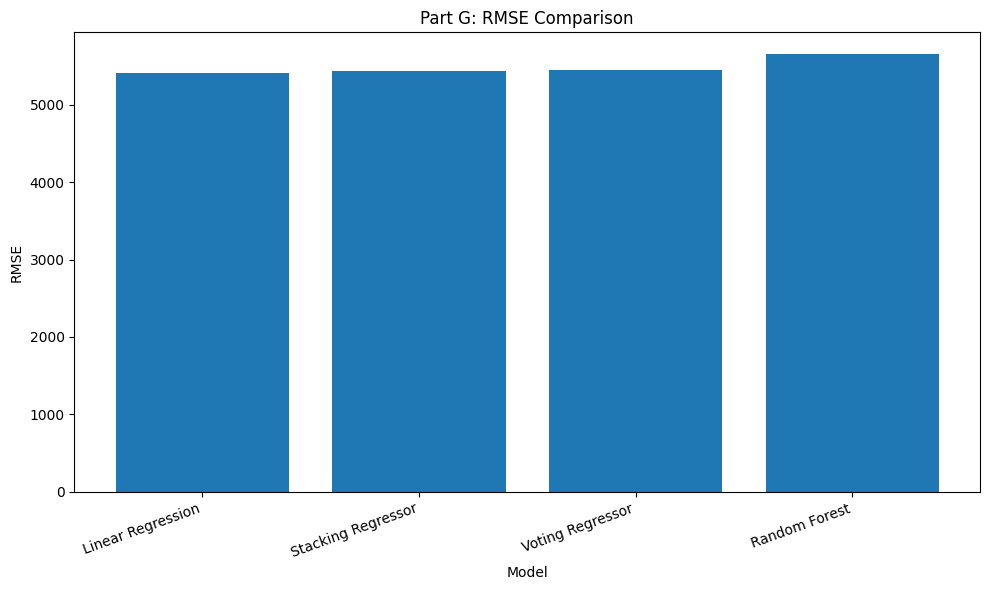

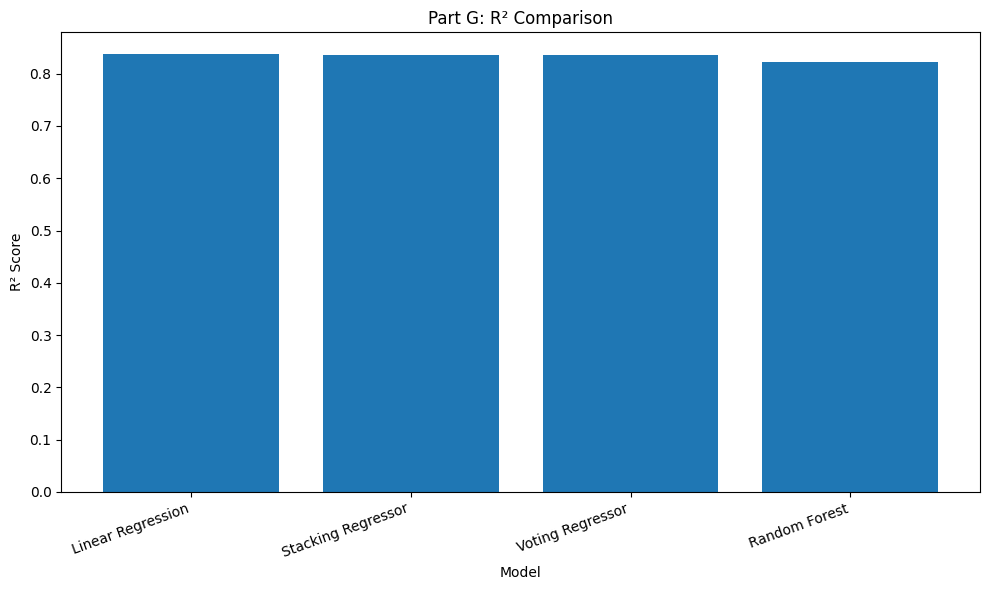

Comparison charts saved.

BEST MODEL COMPARISON
Best model based on RMSE: Linear Regression | RMSE: 5412.3639
Best model based on MAE: Voting Regressor | MAE: 1494.8253
Best model based on R²: Linear Regression | R²: 0.8372

Part G output package created:
/content/Part_G_Ensemble_Results.zip

Files included:
- ensemble_predictions.csv
- voting_regressor.pkl
- ensemble_results.csv
- stacking_regressor.pkl
- r2_comparison.png
- rmse_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# part G

import os
import glob
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shutil
import zipfile
from google.colab import files
from google.colab import drive

from scipy import sparse
from sklearn.base import clone
from sklearn.ensemble import VotingRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. MOUNT DRIVE AND TRANSFER MODELS
drive.mount('/content/drive')

# Your Google Drive folder containing the uploaded files
DRIVE_DIR = "/content/drive/MyDrive/PKL Files"
DATA_DIR = "/content"

# Copy the Linear Regression model to /content
print("Copying Linear Regression model...")
shutil.copy(os.path.join(DRIVE_DIR, "optimised_linear_regression.pkl"), DATA_DIR)

# Unzip the Random Forest model to /content
print("Unzipping Random Forest model...")
with zipfile.ZipFile(os.path.join(DRIVE_DIR, "optimised_random_forest.zip"), 'r') as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Files successfully transferred!\n")


# 2. CONFIGURATION & FILE CHECKS
LR_FILE = "optimised_linear_regression.pkl"
RF_FILE = "optimised_random_forest.pkl"

X_TRAIN_FILE = "X_train_processed.npz"
X_TEST_FILE = "X_test_processed.npz"

Y_TRAIN_FILE = "y_train.csv"
Y_TEST_FILE = "y_test.csv"

OUTPUT_DIR = "/content/part_g_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# If your target CSV contains multiple numeric columns,
# enter the exact target column name here.
# Otherwise, leave as None for automatic detection.
TARGET_COLUMN = None

print("Configuration completed.")
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)


required_files = {
    "Linear Regression model": LR_FILE,
    "Random Forest model": RF_FILE,
    "X_train": X_TRAIN_FILE,
    "X_test": X_TEST_FILE,
    "y_train": Y_TRAIN_FILE,
    "y_test": Y_TEST_FILE
}

file_paths = {}

for label, filename in required_files.items():

    path = os.path.join(DATA_DIR, filename)

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing file: {path}\n"
            f"Please check the filename and location."
        )

    file_size_mb = os.path.getsize(path) / (1024 ** 2)

    if os.path.getsize(path) == 0:
        raise ValueError(f"The file is empty: {path}")

    file_paths[label] = path

    print(
        f"Found: {label} | "
        f"{filename} | "
        f"{file_size_mb:.2f} MB"
    )

print("\nAll required file paths found.\n")


# 3. LOAD OPTIMISED MODELS
lr_model = joblib.load(file_paths["Linear Regression model"])
print("Linear Regression model loaded successfully.")

rf_model = joblib.load(file_paths["Random Forest model"])
print("Random Forest model loaded successfully.")

print("\nBoth optimised models loaded.")

print("\nModel information:")
print("Linear Regression:", type(lr_model).__name__)
print("Random Forest:", type(rf_model).__name__)

if hasattr(lr_model, "n_features_in_"):
    print("Linear Regression features:", lr_model.n_features_in_)

if hasattr(rf_model, "n_features_in_"):
    print("Random Forest features:", rf_model.n_features_in_)


# 4. LOAD PROCESSED FEATURES
def load_features(path):
    try:
        # First attempt: SciPy sparse matrix
        return sparse.load_npz(path)
    except Exception:
        # Second attempt: NumPy NPZ
        data = np.load(path, allow_pickle=False)
        if len(data.files) == 1:
            return data[data.files[0]]
        if "arr_0" in data.files:
            return data["arr_0"]
        raise ValueError(
            f"Could not identify the feature array in {path}. "
            f"Available arrays: {data.files}"
        )

X_train = load_features(file_paths["X_train"])
X_test = load_features(file_paths["X_test"])

print("\nFeature datasets loaded.")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


# 5. LOAD TARGET DATASETS
def load_target(path, target_column=None):
    df = pd.read_csv(path)

    # Remove automatically generated index columns
    unnamed = [
        col for col in df.columns
        if str(col).lower().startswith("unnamed:")
    ]

    if unnamed:
        df = df.drop(columns=unnamed)

    if target_column is not None:
        if target_column not in df.columns:
            raise ValueError(
                f"Target column '{target_column}' "
                f"not found in {path}. Columns: {list(df.columns)}"
            )
        target = df[target_column]
    else:
        numeric_columns = df.select_dtypes(
            include=[np.number]
        ).columns.tolist()

        if len(numeric_columns) != 1:
            raise ValueError(
                f"Could not automatically identify one target "
                f"column in {path}. Numeric columns found: "
                f"{numeric_columns}. Set TARGET_COLUMN in Cell 1."
            )
        target = df[numeric_columns[0]]

    return pd.to_numeric(target, errors="raise").to_numpy()

y_train = load_target(
    file_paths["y_train"],
    TARGET_COLUMN
)

y_test = load_target(
    file_paths["y_test"],
    TARGET_COLUMN
)

print("\nTarget datasets loaded.")
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


# 6. CHECK DATA CONSISTENCY
assert X_train.shape[0] == len(y_train), (
    "X_train and y_train have different row counts."
)

assert X_test.shape[0] == len(y_test), (
    "X_test and y_test have different row counts."
)

assert X_train.shape[1] == X_test.shape[1], (
    "Training and testing feature counts do not match."
)

for name, model in [
    ("Linear Regression", lr_model),
    ("Random Forest", rf_model)
]:
    if hasattr(model, "n_features_in_"):
        assert model.n_features_in_ == X_train.shape[1], (
            f"{name} expects {model.n_features_in_} features, "
            f"but X_train has {X_train.shape[1]}."
        )

print("\nAll dataset consistency checks passed.\n")


# 7. CREATE VOTING REGRESSOR
voting_model = VotingRegressor(
    estimators=[
        ("linear_regression", clone(lr_model)),
        ("random_forest", clone(rf_model))
    ],
    weights=[1, 1],
    n_jobs=-1
)

print("Voting Regressor created.")


# 8. CREATE STACKING REGRESSOR
cv_strategy = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

stacking_model = StackingRegressor(
    estimators=[
        ("linear_regression", clone(lr_model)),
        ("random_forest", clone(rf_model))
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=cv_strategy,
    n_jobs=-1,
    passthrough=False
)

print("Stacking Regressor created.")
print("Final estimator: Ridge Regression")
print("Cross-validation folds: 3\n")


# 9 & 10. FIT ENSEMBLE MODELS
print("Fitting Voting Regressor...")
voting_model.fit(X_train, y_train)
print("Voting Regressor fitted.")

print("\nFitting Stacking Regressor (this may take a few minutes)...")
stacking_model.fit(X_train, y_train)
print("Stacking Regressor fitted.\n")


# 11. GENERATE TEST PREDICTIONS
print("Generating predictions...")

predictions = {
    "Linear Regression": lr_model.predict(X_test),
    "Random Forest": rf_model.predict(X_test),
    "Voting Regressor": voting_model.predict(X_test),
    "Stacking Regressor": stacking_model.predict(X_test)
}

print("Predictions generated.")


# 12. CALCULATE PERFORMANCE METRICS
results = []

for model_name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("\nPART G - ENSEMBLE LEARNING RESULTS")
print("=" * 75)
print(results_df.to_string(index=False))

# Save evaluation results
results_path = os.path.join(
    OUTPUT_DIR,
    "ensemble_results.csv"
)

results_df.to_csv(results_path, index=False)

print("\nResults saved to:", results_path)


# 13. SAVE TEST PREDICTIONS
prediction_df = pd.DataFrame({
    "Actual": y_test,
    "Linear_Regression_Prediction": predictions["Linear Regression"],
    "Random_Forest_Prediction": predictions["Random Forest"],
    "Voting_Prediction": predictions["Voting Regressor"],
    "Stacking_Prediction": predictions["Stacking Regressor"]
})

prediction_path = os.path.join(
    OUTPUT_DIR,
    "ensemble_predictions.csv"
)

prediction_df.to_csv(prediction_path, index=False)

print("Predictions saved:", prediction_path)


# 14. SAVE TRAINED ENSEMBLE MODELS
voting_path = os.path.join(
    OUTPUT_DIR,
    "voting_regressor.pkl"
)

stacking_path = os.path.join(
    OUTPUT_DIR,
    "stacking_regressor.pkl"
)

joblib.dump(voting_model, voting_path, compress=3)
joblib.dump(stacking_model, stacking_path, compress=3)

print("Voting model saved:", voting_path)
print("Stacking model saved:", stacking_path)


# 15. RMSE COMPARISON
plt.figure(figsize=(10, 6))
plt.bar(
    results_df["Model"],
    results_df["RMSE"]
)

plt.title("Part G: RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

rmse_chart = os.path.join(
    OUTPUT_DIR,
    "rmse_comparison.png"
)

plt.savefig(rmse_chart, dpi=300)
plt.show()


# 16. R2 COMPARISON
plt.figure(figsize=(10, 6))
plt.bar(
    results_df["Model"],
    results_df["R2"]
)

plt.title("Part G: R² Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

r2_chart = os.path.join(
    OUTPUT_DIR,
    "r2_comparison.png"
)

plt.savefig(r2_chart, dpi=300)
plt.show()

print("Comparison charts saved.")


# 17. IDENTIFY BEST MODEL
best_rmse_model = results_df.loc[
    results_df["RMSE"].idxmin()
]

best_mae_model = results_df.loc[
    results_df["MAE"].idxmin()
]

best_r2_model = results_df.loc[
    results_df["R2"].idxmax()
]

print("\nBEST MODEL COMPARISON")
print("=" * 50)

print(
    "Best model based on RMSE:",
    best_rmse_model["Model"],
    "| RMSE:",
    round(best_rmse_model["RMSE"], 4)
)

print(
    "Best model based on MAE:",
    best_mae_model["Model"],
    "| MAE:",
    round(best_mae_model["MAE"], 4)
)

print(
    "Best model based on R²:",
    best_r2_model["Model"],
    "| R²:",
    round(best_r2_model["R2"], 4)
)


# 18. CREATE ZIP FILE
zip_path = shutil.make_archive(
    "/content/Part_G_Ensemble_Results",
    "zip",
    OUTPUT_DIR
)

print("\nPart G output package created:")
print(zip_path)

print("\nFiles included:")
for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)

files.download("/content/Part_G_Ensemble_Results.zip")